# Лабораторная работа №2
## Численное интегрирование и дифференцирование
### Вариант 27

**Дисциплина:** Вычислительная математика. Практикум  
**Библиотеки:** NumPy, SciPy, Matplotlib

---

## Цель работы

Реализовать и исследовать:

- составную формулу **средних прямоугольников**;
- составную формулу **трапеций**;
- составную формулу **Симпсона**;
- **правую** и **центральную** разностные формулы для первой производной.

В работе необходимо не только получить численный результат, но и исследовать, **как погрешность зависит от шага $h$**.

> Ячейки с пометкой `TODO` заполняются самостоятельно.  
> Запускайте блокнот сверху вниз. Собственные реализации должны использоваться в основном эксперименте; библиотечные функции нужны для независимой проверки.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import quad

np.set_printoptions(precision=10, suppress=True)

plt.rcParams["figure.figsize"] = (8, 4.8)
plt.rcParams["font.size"] = 12

print("Среда готова к работе.")

Среда готова к работе.


# 1. Исходные данные

## 1.1. Численное интегрирование

В основной части работы используется функция

$$
f(x)= \sqrt{2+x^2}
$$

на отрезке

$$
[a,b]=[0,1].
$$

Необходимо приближённо вычислить

$$
I=\int_0^1 \sqrt{2+x^2}\,dx.
$$

Отрезок разбивается на $n$ равных частей. Шаг сетки:

$$
h=\frac{b-a}{n}.
$$

Чем больше $n$, тем меньше $h$ и тем подробнее сетка.

Для проверки результатов будет использоваться `scipy.integrate.quad`.

In [2]:
def f_int(x):
    return np.sqrt(2 + x**2)


a = 0.0
b = 1.0

reference_integral, quad_error = quad(f_int, a, b)

print(f"Эталонное значение quad: {reference_integral:.12f}")
print(f"Оценка ошибки quad:       {quad_error:.3e}")

Эталонное значение quad: 1.524504352247
Оценка ошибки quad:       1.693e-14


## 1.2. Численное дифференцирование

Для исследования конечных разностей используется

$$
g(x)=\frac{1}{2+x}
$$

в точке

$$
x_0={0.5}
$$

Точное значение производной известно:

$$
g'(x)=\frac{-1}{(2+x)^2},
\qquad
g'(x_0)=\frac{-1}{(2+0.5)^2}.
$$

Здесь $h$ означает небольшое смещение от точки $x_0$.

In [3]:
def f_diff(x):
    return 1 / (2 + x)


x0 = 0.5
exact_derivative = -1 / (2 + x0) ** 2

print(f"x0 = {x0:.8f}")
print(f"Точная производная = {exact_derivative:.12f}")

x0 = 0.50000000
Точная производная = -0.160000000000


# 2. Составные квадратурные формулы

Все три метода приближают площадь под графиком функции, но делают это по-разному.

## Средние прямоугольники

$$
I_M=
h\sum_{i=0}^{n-1}
f\left(x_i+\frac{h}{2}\right).
$$

Функция вычисляется **в середине каждого подынтервала**.

## Трапеции

$$
I_T=
\frac{h}{2}
\left(
y_0+
2\sum_{i=1}^{n-1}y_i+
y_n
\right),
$$

где $y_i=f(x_i)$.

## Симпсон

При **чётном** $n$:

$$
I_S=
\frac{h}{3}
\left[
y_0+
4\sum_{\substack{i=1\\i\text{ нечёт}}}^{n-1}y_i+
2\sum_{\substack{i=2\\i\text{ чёт}}}^{n-2}y_i+
y_n
\right].
$$

Для Симпсона веса внутренних узлов чередуются:

$$
1,\ 4,\ 2,\ 4,\ 2,\ldots,\ 4,\ 1.
$$

Теоретические порядки:

- средние прямоугольники — $O(h^2)$;
- трапеции — $O(h^2)$;
- Симпсон — $O(h^4)$.

## Задание 2.1. Реализация квадратур

Реализуйте три функции:

```python
midpoint_rule(f, a, b, n)
trapezoid_rule(f, a, b, n)
simpson_rule(f, a, b, n)
```

Требования:

- `n` — положительное целое число;
- функция Симпсона должна отклонять нечётное `n`;
- функции должны **возвращать одно число** — приближённое значение интеграла;
- в основной реализации нельзя заменять собственные формулы вызовом готовой квадратурной функции SciPy.

In [4]:
def midpoint_rule(f, a, b, n):
    # TODO:
    # 1. Проверить n
    # 2. Вычислить h
    # 3. Найти середины подынтервалов
    # 4. Применить формулу средних прямоугольников
    if n < 1:
        raise ValueError("n должно быть положительным, больше 1")
    if b <= a:
        raise ValueError("Должно выполняться b > a")
        
    h = (b - a) / n
    x_i = np.linspace(a, b - h, n) + h / 2
    return h * np.sum(f(x_i))


def trapezoid_rule(f, a, b, n):
    # TODO:
    # 1. Проверить n
    # 2. Построить узлы x_i
    # 3. Вычислить y_i = f(x_i)
    # 4. Применить составную формулу трапеций
    if n < 1:
        raise ValueError("n должно быть положительным, больше 1")
    if b <= a:
        raise ValueError("Должно выполняться b > a")
        
    x_i = np.linspace(a, b, n + 1)
    y_i = f(x_i)
    h = (b - a) / n
    
    return (h / 2) * (y_i[0] + 2 * np.sum(y_i[1:-1]) + y_i[-1])


def simpson_rule(f, a, b, n):
    # TODO:
    # 1. Проверить n
    # 2. Отдельно проверить, что n чётное
    # 3. Построить узлы и значения функции
    # 4. Отдельно просуммировать нечётные и чётные внутренние узлы
    # 5. Применить формулу Симпсона
    if n < 1:
        raise ValueError("n должно быть положительным, больше 1")
    if b <= a:
        raise ValueError("Должно выполняться b > a")
    if n % 2:
        raise ValueError("n должно быть четным")

    h = (b - a) / n
    x_i = np.linspace(a, b, n + 1)
    y_i = f(x_i)
    y_odd = y_i[1:-1:2]
    y_even = y_i[2:-1:2]

    return (h / 3) * (y_i[0] + 4 * np.sum(y_odd) + 2 * np.sum(y_even) + y_i[-1])

    

## Быстрая проверка

После реализации запустите методы при `n = 10`.

Результаты должны быть близки к эталонному интегралу, но не обязаны совпадать с ним полностью.

In [5]:
try:
    n_test = 10

    print("quad:                  ", reference_integral)
    print("Средние прямоугольники:", midpoint_rule(f_int, a, b, n_test))
    print("Трапеции:              ", trapezoid_rule(f_int, a, b, n_test))
    print("Симпсон:               ", simpson_rule(f_int, a, b, n_test))

except NotImplementedError:
    print("Сначала реализуйте три квадратурные функции.")

quad:                   1.5245043522468469
Средние прямоугольники: 1.5242637428449701
Трапеции:               1.5249855309436229
Симпсон:                1.5245041381348048


# 3. Исследование точности интегрирования

Выполните расчёты для

$$
n=10,\ 20,\ 40,\ 80,\ 160,\ 320.
$$

Для каждого метода вычислите:

- $n$;
- шаг $h=(b-a)/n$;
- приближённый интеграл $I_n$;
- абсолютную погрешность

$$
E=|I_n-I_{\mathrm{ref}}|.
$$

Результаты удобно хранить в списке словарей или в отдельных массивах.

In [6]:
n_values = [10, 20, 40, 80, 160, 320]

integration_results = []

# TODO:
# Для каждого n:
# 1. вычислить h
# 2. запустить три метода
# 3. вычислить абсолютную ошибку относительно reference_integral
# 4. сохранить результаты
def test_method(method, n_values):
    test_data = {}
    test_data["method"] = method.__name__
    test_data["results"] = []

    for n in n_values:
        data = {}
        res = method(f_int, a, b, n)
        data["n"] = n
        data["h"] =  (b - a) / n
        data["res"] = float(res)
        data["abs_error"] = float(np.abs(res - reference_integral))

        test_data["results"].append(data)
        
    return test_data

        

for method in midpoint_rule, trapezoid_rule, simpson_rule:
    integration_results.append(test_method(method, n_values))
    
    
integration_results

[{'method': 'midpoint_rule',
  'results': [{'n': 10,
    'h': 0.1,
    'res': 1.5242637428449701,
    'abs_error': 0.00024060940187675683},
   {'n': 20,
    'h': 0.05,
    'res': 1.5244442086700887,
    'abs_error': 6.014357675820925e-05},
   {'n': 40,
    'h': 0.025,
    'res': 1.5244893169008646,
    'abs_error': 1.5035345982239434e-05},
   {'n': 80,
    'h': 0.0125,
    'res': 1.524500593444612,
    'abs_error': 3.7588022347989636e-06},
   {'n': 160,
    'h': 0.00625,
    'res': 1.5245034125484296,
    'abs_error': 9.39698417301571e-07},
   {'n': 320,
    'h': 0.003125,
    'res': 1.5245041173223766,
    'abs_error': 2.3492447032147368e-07}]},
 {'method': 'trapezoid_rule',
  'results': [{'n': 10,
    'h': 0.1,
    'res': 1.5249855309436229,
    'abs_error': 0.0004811786967759968},
   {'n': 20,
    'h': 0.05,
    'res': 1.5246246368942964,
    'abs_error': 0.00012028464744950895},
   {'n': 40,
    'h': 0.025,
    'res': 1.5245344227821926,
    'abs_error': 3.0070535345760874e-05},
  

## Задание 3.1. График погрешности

Постройте на одном рисунке зависимости абсолютной погрешности от $h$ для трёх методов.

Используйте **двойной логарифмический масштаб**:

```python
plt.loglog(...)
```

На графике должны быть:

- три кривые;
- подписи осей;
- заголовок;
- сетка;
- легенда.

График должен показать, насколько быстро уменьшается ошибка при уменьшении шага.

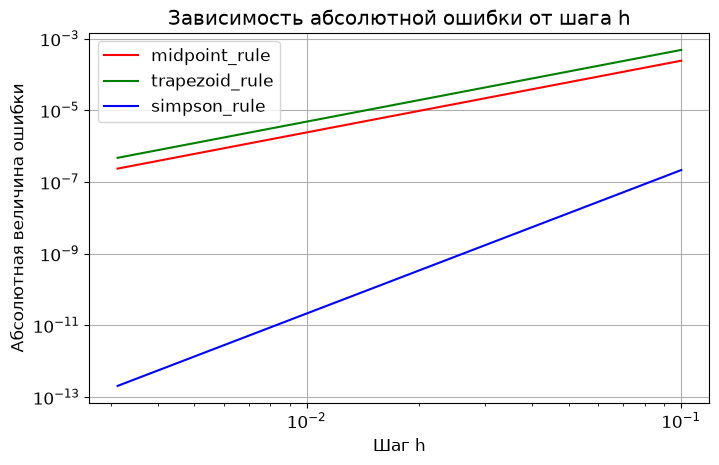

In [7]:
# TODO:
# 1. извлечь h и ошибки из integration_results
# 2. построить три зависимости error(h) через plt.loglog()
# 3. оформить график
def plot_error(error_history, h_history, line, label, marker_size=3):
    plt.loglog(h_history, error_history, line, label=label, markersize=marker_size)

color = {
    "midpoint_rule": 'r', 
    "trapezoid_rule": 'g', 
    "simpson_rule": 'b'
}

for method in integration_results:
    h_history, err_history = [], []
    for test in method['results']:
        h_history.append(test['h'])
        err_history.append(test['abs_error'])
    plot_error(err_history, h_history, f'{color[method["method"]]}-', method["method"])

plt.grid(True)
plt.legend()
plt.title("Зависимость абсолютной ошибки от шага h")
plt.xlabel("Шаг h")
plt.ylabel("Абсолютная величина ошибки")

plt.show()

# 4. Эмпирический порядок точности

Если погрешность метода ведёт себя как

$$
E(h)\approx Ch^p,
$$

то после логарифмирования:

$$
\log E \approx \log C + p\log h.
$$

Это уравнение прямой. Поэтому коэффициент наклона графика

$$
\log E \quad\text{от}\quad \log h
$$

приближённо равен порядку метода $p$.

Для оценки наклона можно использовать:

```python
p, _ = np.polyfit(np.log(h_values), np.log(errors), 1)
```

## Задание 4.1

Оцените эмпирический порядок каждого метода и сравните его с теорией:

- прямоугольники: $p\approx2$;
- трапеции: $p\approx2$;
- Симпсон: $p\approx4$.

In [8]:
# TODO:
# Для каждого метода:
# p, _ = np.polyfit(np.log(h_values), np.log(errors), 1)

ps = []
for method in integration_results:
    h_history, err_history = [], []
    for test in method['results']:
        h_history.append(test['h'])
        err_history.append(test['abs_error'])
    p, _ = np.polyfit(np.log(h_history), np.log(err_history), 1)
    ps.append(p)

print("Средние прямоугольники: p =", ps[0])
print("Трапеции:               p =", ps[1])
print("Симпсон:                p =", ps[2])

Средние прямоугольники: p = 2.000046337056822
Трапеции:               p = 2.0000264783620874
Симпсон:                p = 4.000623947561543


# 5. Численное дифференцирование

Для первой производной реализуйте две формулы.

## Правая разность

$$
g'(x)\approx
\frac{g(x+h)-g(x)}{h}.
$$

Теоретический порядок:

$$
O(h).
$$

## Центральная разность

$$
g'(x)\approx
\frac{g(x+h)-g(x-h)}{2h}.
$$

Теоретический порядок:

$$
O(h^2).
$$

## Задание 5.1

Реализуйте:

```python
forward_diff(f, x, h)
central_diff(f, x, h)
```

Функции должны возвращать приближённое значение первой производной.

In [9]:
def forward_diff(f, x, h):
    # TODO: реализовать правую разность
    return (f(x + h) - f(x)) / h


def central_diff(f, x, h):
    # TODO: реализовать центральную разност
    return (f(x + h) - f(x - h)) / (2 * h)

# 6. Влияние шага при дифференцировании

Исследуйте шаги

$$
h=10^{-1},10^{-2},\ldots,10^{-15}.
$$

Для каждого $h$ вычислите:

- правую разность;
- центральную разность;
- абсолютную ошибку относительно

$$
g'(x_0)=\cos x_0.
$$

Затем постройте обе зависимости ошибки от $h$ на одном **log-log графике**.

Обратите внимание: ошибка не обязана уменьшаться до самого маленького $h$.

In [10]:
h_values_diff = 10.0 ** (-np.arange(1, 16))

forward_errors = []
central_errors = []

# TODO:
# Для каждого h:
# 1. вычислить обе производные
# 2. сравнить с exact_derivative
# 3. сохранить абсолютные ошибки
for h in h_values_diff:
    forward_errors.append(np.abs(forward_diff(f_diff, x0, h) - exact_derivative))
    central_errors.append(np.abs(central_diff(f_diff, x0, h) - exact_derivative))
    

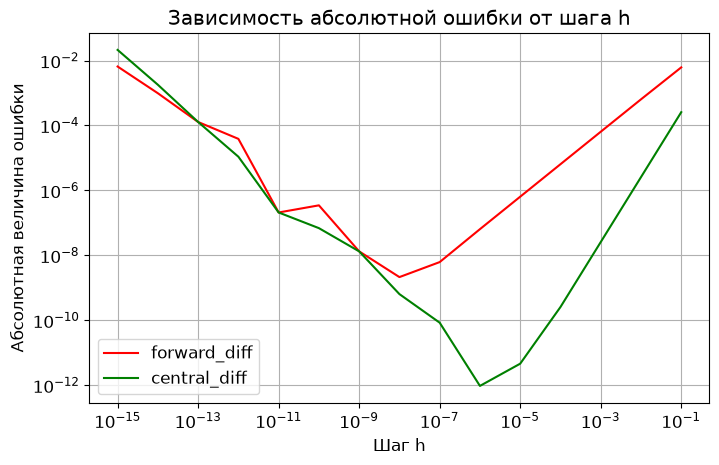

In [11]:
# TODO:
# Построить на одном рисунке:
# - ошибку правой разности
# - ошибку центральной разности
#
# Использовать log-log масштаб.

def plot_error(error_history, h_history, line, label, marker_size=3):
    plt.loglog(h_history, error_history, line, label=label, markersize=marker_size)

plot_error(forward_errors, h_values_diff,'r-', "forward_diff")
plot_error(central_errors, h_values_diff, 'g-', "central_diff")

plt.grid(True)
plt.legend()
plt.title("Зависимость абсолютной ошибки от шага h")
plt.xlabel("Шаг h")
plt.ylabel("Абсолютная величина ошибки")

plt.show()

## Задание 6.1. Найдите лучший шаг

Для каждой формулы определите:

- при каком $h$ абсолютная ошибка минимальна;
- чему равна эта минимальная ошибка.

Например, индекс минимума можно получить через:

```python
idx = np.argmin(errors)
```

### Что необходимо объяснить

При уменьшении $h$ сначала уменьшается **ошибка аппроксимации**.

Но при очень маленьком $h$ приходится вычитать почти равные числа:

$$
f(x+h)-f(x)
$$

или

$$
f(x+h)-f(x-h).
$$

Из-за конечной точности `float64` усиливается ошибка округления. Поэтому на графике возникает минимум: **слишком маленький шаг тоже может ухудшать результат**.

In [16]:
# TODO:
# Найти h и ошибку в точке минимума для обеих формул.
forward_idx = np.argmin(forward_errors)
central_idx = np.argmin(central_errors)

print("Правая разность: лучший h =", h_values_diff[forward_idx], forward_errors[forward_idx])
print("Центральная разность: лучший h =", h_values_diff[central_idx], central_errors[central_idx])

Правая разность: лучший h = 1e-08 2.1362291102722253e-09
Центральная разность: лучший h = 1e-06 9.502121312010559e-13


# 7. Сравнение с библиотечными реализациями

Библиотечные функции используются **только как независимая проверка** собственных реализаций.

## 7.1. Интегрирование

Сравните один из достаточно точных собственных результатов, например при `n = 320`, с:

```python
scipy.integrate.quad
```

Выведите абсолютное отличие.

In [17]:
# TODO:
# Вычислить собственные результаты при n = 320
# и сравнить каждый из них с reference_integral.

for method in midpoint_rule, trapezoid_rule, simpson_rule:
    print(method.__name__, np.abs(reference_integral - method(f_int, a, b, 320)))

midpoint_rule 2.3492447032147368e-07
trapezoid_rule 4.698489031174091e-07
simpson_rule 2.036149027162537e-13


## 7.2. Дифференцирование

Для сравнения с `numpy.gradient` выберите разумный шаг, например

$$
h=10^{-3}.
$$

Создайте три точки:

$$
x_0-h,\quad x_0,\quad x_0+h,
$$

вычислите значения функции и вызовите `np.gradient`.

Сравните значение производной в центральной точке:

- с точной производной;
- со своей `central_diff`.

In [18]:
h_check = 1e-3

# TODO:
# x_check = ...
# y_check = ...
# grad = np.gradient(...)
#
# Сравнить grad[1], central_diff(...) и exact_derivative.

x_check = np.array([x0 - h_check, x0, x0 + h_check])
y_check = f_diff(x_check)

grad = np.gradient(y_check, x_check)[1]

print("grad и centreal_diff: ", np.abs(grad - central_diff(f_diff, x0, h_check)))
print("grad и exact_derivative: ", np.abs(grad - exact_derivative))
print("centreal_diff и exact_derivative: ", np.abs(central_diff(f_diff, x0, h_check) - exact_derivative))


grad и centreal_diff:  1.3877787807814457e-16
grad и exact_derivative:  2.5599987685254177e-08
centreal_diff и exact_derivative:  2.5599987824032056e-08


# 8. Анализ результатов

В отчёте необходимо сделать выводы **по своим вычислениям**, а не просто переписать формулы.

Ответьте кратко.

### 8.1. Интегрирование

- Как меняется ошибка при увеличении $n$?
- Какие эмпирические порядки получены?
- Соответствуют ли они $2,\ 2,\ 4$?
- Какой метод на исследованной функции дал наименьшую ошибку при одинаковом $n$?

**Ответ:** 
- При увеличении $n$ шаг h уменьшается и абсолютная погрешность всех трех методов уменьшается.
- Эмпирические порядки примерно соответствуют теоретическим, так средние прямоугольники и правило трапеции дали $p = 2$, а метод Симпсона $p=4$
- Наименьшую абсолютную ошибку при интегрировании данной функции при одинаковом $n$ показывает метод Симпсона, что подтверждает его порядок сходимости

### 8.2. Дифференцирование

- Какая формула точнее при умеренных значениях $h$?
- При каком $h$ ошибка каждой формулы оказалась минимальной?
- Почему дальнейшее уменьшение $h$ ухудшает результат?

**Ответ:**
- При умеренных значениях $h$ центральная разность точнее правой.
- Для правой разности точкой оптимума является $h = 10^{-8}$, а для центральной — $h = 10^{-6}$
- Потому что существует точка оптимума, после прохождения которой в числителе обеих формул начинается вычитание близких чисел, что приводит к катастрофической отмене и потери точности. 

### 8.3. Проверка библиотеками

- Насколько собственные результаты согласуются с `quad`?
- Как соотносятся `central_diff` и `numpy.gradient` на выбранной сетке?

**Ответ:**
- Собственные квадратурные формулы хорошо согласуются с `scipy.integrate.quad`. При $n=320$ значения по методу средних прямоугольников и правилу трапеции отличается от эталонного на $10^{-7}$, а по методу Симпсона — $10^{-13}$, что согласуется с их порядками сходимости.
- `central_diff` и `numpy.gradient` на выбранной сетке отличаются всего лишь на $10^{-16}$, то есть достигается уровень машинной точности float64; также они дают примерно одинаковую ошибку в $10^{-8}$ по сравнению с точным значением

# 9. Требования к отчёту

Отчёт оформляется в **PDF**.

Рекомендуемая структура:

1. **Титульный лист**.
2. **Содержание (на отдельной странице**.
3. **Цель работы + Краткая теория** — используемые формулы и их теоретические порядки; без подробного переписывания методички.
4. **Описание реализации** — основные функции и особенности алгоритмов.
5. **Результаты**:
   - таблица значений интеграла и погрешностей при разных $n$;
   - log-log график погрешностей интегрирования;
   - найденные эмпирические порядки $p$;
   - log-log график погрешностей численного дифференцирования;
   - лучший шаг $h$ для каждой разностной формулы;
   - сравнение с `quad` и `numpy.gradient`.
6. **Выводы** — объяснение полученных закономерностей.
7. При необходимости — приложение с полным листингом.

## Требования к графикам

Каждый график должен иметь:

- заголовок;
- подписи осей;
- сетку;
- легенду, если показано несколько кривых;
- читаемый масштаб.

Для зависимостей погрешности от шага используйте логарифмический масштаб.

## Требования к таблицам

- понятные названия столбцов;
- одинаковая разумная точность для однотипных величин;
- рядом с результатами должна быть указана погрешность;
- таблицы и графики необходимо прокомментировать в тексте.

## Воспроизводимость

Перед сдачей:

1. перезапустите ядро;
2. выполните все ячейки **сверху вниз**;
3. убедитесь, что блокнот работает без ручного изменения переменных между ячейками.

# 10. Возможные вопросы на защите

Преподаватель может попросить объяснить формулу, полученный график или небольшой участок собственного кода.

## Основные вопросы

1. Что означает шаг $h$ при численном интегрировании?
2. Чем средние прямоугольники отличаются от трапеций геометрически?
3. Как распределяются веса в составной формуле Симпсона?
4. Почему для Симпсона число подынтервалов должно быть чётным?
5. Каков теоретический порядок средних прямоугольников, трапеций и Симпсона?
6. Что означает запись $E(h)\sim Ch^p$?
7. Почему наклон log-log графика позволяет оценить порядок $p$?
8. Почему два метода одного порядка могут иметь разные абсолютные ошибки?
9. Чем правая разность отличается от центральной?
10. Каков порядок правой и центральной разности?
11. Почему центральная разность обычно точнее при одинаковом достаточно малом $h$?
12. Почему нельзя считать, что чем меньше $h$, тем производная всегда вычисляется точнее?
13. Что такое ошибка округления при вычитании близких чисел?
14. Зачем сравнивать собственный интегратор с `scipy.integrate.quad`?
15. Что именно сравнивается с `numpy.gradient`?

## Вопросы по вашей реализации и эксперименту

16. Покажите, где в коде формируются середины подынтервалов.
17. Покажите, где в формуле Симпсона разделяются нечётные и чётные узлы.
18. Что сделает ваша функция Симпсона при нечётном `n`?
19. Как именно вы вычислили эмпирический порядок метода?
20. На каком диапазоне значений $h$ ваш график действительно отражает теоретический порядок?
21. Какой минимальный уровень ошибки вы получили при дифференцировании?
22. Почему крайние точки эксперимента могут хуже соответствовать теории?
23. Совпадает ли `numpy.gradient` в центральной точке трёхточечной равномерной сетки с центральной разностью? Почему?

## Возможные небольшие изменения кода на защите

Преподаватель может попросить:

- изменить набор значений `n`;
- передать нечётное `n` в `simpson_rule`;
- уменьшить или увеличить диапазон шагов $h$;
- вывести веса Симпсона для выбранного `n`;
- найти лучший шаг только для одной разностной формулы;
- изменить точку $x_0$;
- построить график только для двух методов;
- повторить оценку порядка по двум соседним ошибкам без `polyfit`.

# 11. Что сдаётся

1. Заполненный и полностью выполняющийся `.ipynb`.
2. Отчёт в формате PDF.

Перед сдачей убедитесь, что все обязательные ячейки выполнены, графики построены, а в разделе анализа записаны собственные выводы.